### **Imports & Data Reading**

In [1]:
import pandas as pd
import numpy as np
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import cv2
import methods
import joblib
from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.utils.extmath import randomized_svd
from sklearn.manifold import TSNE, LocallyLinearEmbedding
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score, silhouette_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyRegressor
from umap import UMAP
from time import perf_counter

### **Questions**

<br>------------------------<br>
**For which of the models already studied is the curse of dimensionality relevant and explain why.**<br>
<br>
    - **Linear/Logistic regression**<br>
    - **KNN**<br>
    - **KMeans**<br>
<br>
**Linear/Logistic regression**<br>
Для линейной и логистической регрессии большое количество признаков при недостаточном количестве объектов повышает риск переобучения. Например, для матрицы размера $m \times n$, где $m$ — количество объектов, а $n$ — количество признаков, такая ситуация возникает при $n \gg m$. Регуляризация помогает уменьшить этот риск.<br>
<br>
**KNN**<br>
Для KNN проклятие размерности проявляется в том, что алгоритм использует расстояния между объектами, и в разреженном пространстве обобщающая способность алгоритма падает. Также для KNN необходима либо нормализация, либо стандартизация данных, т.к разный характер и масштаб признаков могут влиять на расположение объектов в пространстве, и отдалять друг от друга потенциально похожие объекты.<br>
<br>
**KMeans**<br>
То же самое, что и для KNN<br>
<br>------------------------<br>
**What is the difference between PCA and SVD?**<br>
PCA (Principal Component Analysis/Метод главных компонент) требует центрирования исходной матрицы, а SVD (Singular Value Decomposition/Сингулярное разложение) нет. PCA можно вычислить через SVD центрированной матрицы.<br>
<br>------------------------<br>
**What is the difference between NMF and SVD?**<br>
NMF (Non-Negative Matrix Factorization/Неотрицательное матричное разложение) раскладывает матрицу на две другие неотрицательные матрицы, сама разлагаемая матрица должна быть неотрицательной. SVD раскладывает любую вещественную матрицу на три матрицы, из которых >= 0 обязана быть только матрица сингулярных чисел. SVD использует разложение матрицы на множители $U\Sigma V^\top$, $U$ и $V^\top$ - ортогональны. в NMF ортогональность компонентов не требуется.<br>
<br>------------------------<br>
**Describe the structure of the Locally Linear Embedding dimension reduction algorithm.**<br>
Это нелинейный метод снижения размерности, который описывает каждый объект в пространстве засчет k соседних объектов, обучая на них мини-линейную регрессию, засчет чего за этими данными закрепляются опр. коэффициенты. Затем точка приближенно восстанавливается как взвешенная сумма соседей $x_i \approx \sum_{j\in N(i)} w_{ij}x_j$. Веса фиксируются, а для точек ищутся координаты $y_i$ в пространстве меньшей размерности. Они должны как можно лучше сохранять те же зависимости между соседями $min_{\{y_i\}}\sum_i\left\|y_i-\sum_{j\in N(i)}w_{ij}y_j\right\|^2$

### **Data Reading**

In [2]:
users = pd.read_csv('data/Users.csv', low_memory=False)
ratings = pd.read_csv('data/Ratings.csv', low_memory=False)

In [3]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   User-ID   278858 non-null  int64  
 1   Location  278858 non-null  str    
 2   Age       168096 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 6.4 MB


In [4]:
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


**Таргет имеет очень много nan-значений, далее по ходу работы мы все эти строки из users удалим. Также удалим те индексы, что не встречаются в ratings**

In [5]:
print(users['Age'].shape[0], users['Age'].isna().sum())

278858 110762


In [6]:
print(users['Age'].max(), users['Age'].min())

244.0 0.0


In [7]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1149780 entries, 0 to 1149779
Data columns (total 3 columns):
 #   Column       Non-Null Count    Dtype
---  ------       --------------    -----
 0   User-ID      1149780 non-null  int64
 1   ISBN         1149780 non-null  str  
 2   Book-Rating  1149780 non-null  int64
dtypes: int64(2), str(1)
memory usage: 26.3 MB


In [8]:
ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [9]:
len(ratings['User-ID'].unique())

105283

In [10]:
l = users['User-ID'].shape[0]
print(len(users['User-ID'].unique()) == l, l)

True 278858


In [11]:
ratings.isna().any(axis=0)

User-ID        False
ISBN           False
Book-Rating    False
dtype: bool

In [12]:
users.isna().any(axis=0)

User-ID     False
Location    False
Age          True
dtype: bool

### **Creating a Sparse Matrix**

In [13]:
nan_users = users.loc[users['Age'].isna()]

In [14]:
users.dropna(inplace=True)

In [15]:
_, inv = np.unique(ratings['ISBN'], return_inverse=True)
ratings['ISBN'] = np.asarray(inv)
ratings['Book-Rating'] = ratings['Book-Rating'].astype(bool)

ratings = ratings.loc[ratings['User-ID'].isin(users['User-ID'])]
users = users.loc[users['User-ID'].isin(ratings['User-ID'])]

_, inv = np.unique(users['User-ID'], return_inverse=True)
users['User-ID'] = np.asarray(inv)

_, inv = np.unique(ratings['User-ID'], return_inverse=True)
ratings['User-ID'] = np.asarray(inv)

In [16]:
users = users.sort_values(by=['User-ID'])
users.head(10)

,User-ID,Location,Age
1,0,"stockton, california, usa",18.0
9,1,"albacete, wisconsin, spain",26.0
18,2,"weston, ,",14.0
19,3,"langhorne, pennsylvania, usa",19.0
35,4,"montreal, quebec, canada",24.0
37,5,"viterbo, lazio, italy",34.0
41,6,"appleton, wisconsin, usa",17.0
43,7,"black mountain, north carolina, usa",51.0
50,8,"renton, washington, usa",34.0
55,9,"cheyenne, wyoming, usa",24.0


In [17]:
ratings = ratings.sort_values(by=['User-ID', 'ISBN'])
ratings.head(10)

,User-ID,ISBN,Book-Rating
9561,0,32069,False
9584,1,269904,False
9585,1,322257,True
9600,2,74570,True
9601,3,95065,False
9612,4,160779,False
9613,5,328170,False
9614,5,332400,False
9618,6,139545,True
9619,7,95844,False


In [18]:
(users['User-ID'].unique() == ratings['User-ID'].unique()).all()

np.True_

In [19]:
data = np.asarray(ratings['Book-Rating']).astype(int)
row_idx = ratings['User-ID'].values
col_idx = ratings['ISBN'].values

sparse_matrix = csr_matrix((data, (row_idx, col_idx)))
sparse_matrix

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 840288 stored elements and shape (62107, 340556)>

In [20]:
# idx = np.arange(ratings['User-ID'].unique().shape[0])
# userid_idx = np.argsort(ratings['User-ID'].unique())
# idx = idx[userid_idx]

In [21]:
# data = np.ones(user_book_table['Book-Rating'].sum()) #заполняем значениями непустых строк (единичками)
# col = user_book_table.loc[user_book_table['Book-Rating'] == 1]['ISBN'].to_numpy() #находим значения столбцов для каждого непустого значения
# row = np.zeros(ratings['User-ID'].shape[0] + 1)

### **Data Splitting & Preprocessing & Model's training**

In [22]:
X = sparse_matrix.copy()
y = users['Age'].copy()

In [23]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=21)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.5, random_state=21)

In [24]:
x_train.shape, x_val.shape, x_test.shape

((21737, 340556), (21737, 340556), (18633, 340556))

#### **Deleting Outliers**

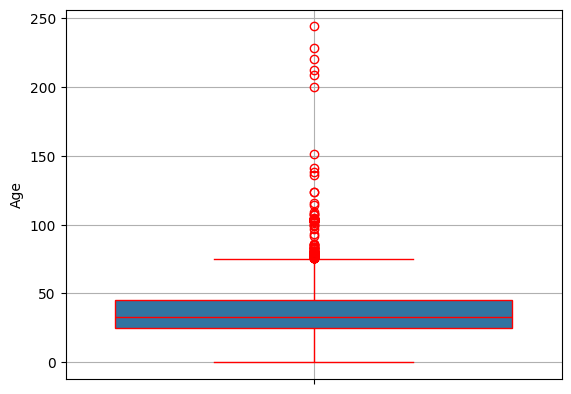

In [25]:
age_values = y_train.copy()

sns.boxplot(age_values, linecolor='red')
plt.grid(True)
plt.show()

In [26]:
q1 = age_values.quantile(0.25)
q3 = age_values.quantile(0.75)

iqr = q3 - q1

upper_border = q3 + 1.5 * iqr

mask = age_values.values < upper_border
y_train = y_train[mask]
x_train = x_train[mask]

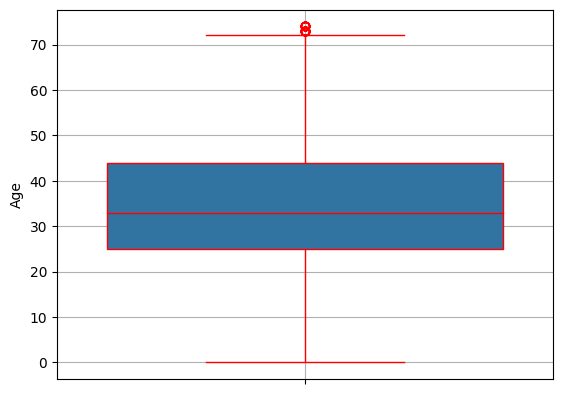

In [27]:
sns.boxplot(y_train, linecolor='red')
plt.grid(True)
plt.show()

**Для правдоподобности удалим также значения <5. Хоть и статистически выбросами они не являются, настолько маленькие значения возраста считаются аномальными с точки зрения логики**

In [28]:
mask = y_train.values >= 5
y_train = y_train[mask]
x_train = x_train[mask]

### **Building linear and random forest models**

In [29]:
importlib.reload(methods)
from methods import study

In [30]:
model_names = ['RandomForest', 'Lasso', 'Ridge', 'ElasticNet']

In [31]:
models_best_params = []

for model_name in model_names:
    print(f"{model_name}:")
    models_best_params.append(study(x_train, x_val, y_train, y_val, model_name, n_trials=10))

[I 2026-11-04 21:51:58,934] A new study created in memory with name: no-name-f65725f5-3d59-46da-800c-1e4925a47ab3


RandomForest:


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 21:55:44,741] Trial 0 finished with value: 14.813462828061938 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 6, 'min_samples_leaf': 12, 'max_features': None}. Best is trial 0 with value: 14.813462828061938.
[I 2026-11-04 21:55:45,450] Trial 1 finished with value: 14.894909260300041 and parameters: {'n_estimators': 500, 'max_depth': 10, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 'log2'}. Best is trial 0 with value: 14.813462828061938.
[I 2026-11-04 21:59:53,850] Trial 2 finished with value: 14.838327776784524 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None}. Best is trial 0 with value: 14.813462828061938.
[I 2026-11-04 21:59:54,352] Trial 3 finished with value: 14.896412380979827 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 24, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 0 with value: 14.81346282806193

[I 2026-11-04 22:02:40,523] A new study created in memory with name: no-name-663a2fbc-a2a1-4bb2-a621-1c0cd47930cf


[I 2026-11-04 22:02:40,520] Trial 9 finished with value: 14.862812452782812 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 6 with value: 14.813368293222148.
Lasso:


... (6 outputs left out)

[I 2026-11-04 22:03:51,587] A new study created in memory with name: no-name-cd719ee0-b46c-4ac2-915e-09d2ff50b1af


[I 2026-11-04 22:03:51,490] Trial 8 finished with value: 16.716857713009308 and parameters: {'alpha': 0.821162683297018, 'tol': 0.004729251785436346, 'solver': 'sag', 'max_iter': 100}. Best is trial 3 with value: 16.569898404149452.
[I 2026-11-04 22:03:51,586] Trial 9 finished with value: 16.66794725261753 and parameters: {'alpha': 0.85140597826459, 'tol': 0.003714611243735656, 'solver': 'sag', 'max_iter': 700}. Best is trial 3 with value: 16.569898404149452.
ElasticNet:


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 22:03:58,557] Trial 0 finished with value: 14.89612234316614 and parameters: {'alpha': 0.058237632001036016, 'l1_ratio': 0.2962185631919187, 'max_iter': 1000, 'tol': 0.005172248343868142}. Best is trial 0 with value: 14.89612234316614.
[I 2026-11-04 22:04:05,523] Trial 1 finished with value: 14.896480557873632 and parameters: {'alpha': 0.3092491750249707, 'l1_ratio': 0.667271191678453, 'max_iter': 1500, 'tol': 0.08675370795090953}. Best is trial 0 with value: 14.89612234316614.
[I 2026-11-04 22:04:12,483] Trial 2 finished with value: 14.896480557873632 and parameters: {'alpha': 0.14190811405923026, 'l1_ratio': 0.18634341494390336, 'max_iter': 1500, 'tol': 0.09705146402238085}. Best is trial 0 with value: 14.89612234316614.
[I 2026-11-04 22:04:19,442] Trial 3 finished with value: 14.896480557873632 and parameters: {'alpha': 0.7617095272576972, 'l1_ratio': 0.3904075317692281, 'max_iter': 1500, 'tol': 0.08542487691193527}. Best is trial 0 with value: 14.89612234316614.
[I 20

In [32]:
models_best_params = sorted(models_best_params, key=lambda x: x[1])
for model_name, best_rmse, _ in models_best_params:
    print(f'{model_name} RMSE: {best_rmse}')

RandomForest RMSE: 14.813368293222148
ElasticNet RMSE: 14.89612234316614
Lasso RMSE: 14.896480557873632
Ridge RMSE: 16.569898404149452


**Best RF and Linear model**

In [33]:
models_best_param_dict = {model_name: params for model_name, _, params in models_best_params}

In [34]:
rf = RandomForestRegressor(**models_best_param_dict['RandomForest'], n_jobs=-1, random_state=21)
lasso = Lasso(**models_best_param_dict['Lasso'], random_state=21)
ridge = Ridge(**models_best_param_dict['Ridge'], random_state=21)
en = ElasticNet(**models_best_param_dict['ElasticNet'], random_state=21)

In [35]:
metrics = pd.DataFrame(columns=['model + method', 'fit_time', 'train_rmse', 'test_rmse', 'train_r2', 'test_r2'])

**Random Forest**

In [36]:
rf_timing = %timeit -o -r 1 -n 1 rf.fit(x_train, y_train);

2min 16s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [37]:
train_pred_rf = rf.predict(x_train)
test_pred_rf = rf.predict(x_test)

In [38]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('RF + no method', f"{rf_timing.average:.6f} s", y_train, train_pred_rf, y_test, test_pred_rf, metrics)

**ElasticNet model**

In [39]:
en_timing = %timeit -o -r 1 -n 1 en.fit(x_train, y_train)

6.98 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [40]:
train_pred_en = en.predict(x_train)
test_pred_en = en.predict(x_test)

In [41]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('ElasticNet + no method', f"{en_timing.average:6f} s", y_train, train_pred_en, y_test, test_pred_en, metrics)

**Lasso model**

In [42]:
lasso_timing = %timeit -o -r 1 -n 1 lasso.fit(x_train, y_train)

7 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [43]:
train_pred_lasso = lasso.predict(x_train)
test_pred_lasso = lasso.predict(x_test)

In [44]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('Lasso + no method', f"{lasso_timing.average:6f} s", y_train, train_pred_lasso, y_test, test_pred_lasso, metrics)

**Ridge model**

In [45]:
ridge_timing = %timeit -o -r 1 -n 1 ridge.fit(x_train, y_train)

104 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [46]:
train_pred_ridge = ridge.predict(x_train)
test_pred_ridge = ridge.predict(x_test)

In [47]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('Ridge + no method', f"{ridge_timing.average:6f} s", y_train, train_pred_ridge, y_test, test_pred_ridge, metrics)

**Models with no dimensial reduction method**

In [48]:
metrics

,model + method,fit_time,train_rmse,test_rmse,train_r2,test_r2
0,RF + no method,136.488268 s,13.30329,14.583414,0.018832,0.009295
1,ElasticNet + no method,6.983437 s,13.429972,14.651621,0.000057,0.000006
2,Lasso + no method,7.003885 s,13.430353,14.651904,0.0,-0.000033
3,Ridge + no method,0.104188 s,8.722917,15.947468,0.578159,-0.184703


### **Applying PCA and UMAP**

#### **PCA**

In [49]:
pca = PCA(n_components=100, random_state=21)
start = perf_counter()
pca_x_train = pca.fit_transform(x_train)
pca_time = perf_counter() - start
pca_x_val = pca.transform(x_val)
pca_x_test = pca.transform(x_test)

In [50]:
importlib.reload(methods)

models_best_params_pca = []

for model_name in model_names:
    print(f"{model_name}:")
    models_best_params_pca.append(study(pca_x_train, pca_x_val, y_train, y_val, model_name))

[I 2026-11-04 22:07:36,057] A new study created in memory with name: no-name-524febd3-c5c2-4ca9-b5b1-7b7e7b592d7d


RandomForest:


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 22:08:22,559] Trial 0 finished with value: 14.632362119608867 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 6, 'min_samples_leaf': 12, 'max_features': None}. Best is trial 0 with value: 14.632362119608867.
[I 2026-11-04 22:08:24,985] Trial 1 finished with value: 14.625976124511396 and parameters: {'n_estimators': 500, 'max_depth': 10, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 'log2'}. Best is trial 1 with value: 14.625976124511396.
[I 2026-11-04 22:09:19,722] Trial 2 finished with value: 14.823685471185243 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None}. Best is trial 1 with value: 14.625976124511396.
[I 2026-11-04 22:09:22,877] Trial 3 finished with value: 14.634377114665993 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 24, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 1 with value: 14.62597612451139

[I 2026-11-04 22:09:57,693] A new study created in memory with name: no-name-7c1df40b-4a09-44e2-8829-6a354218558e


[I 2026-11-04 22:09:57,691] Trial 9 finished with value: 14.64055680423313 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 1 with value: 14.625976124511396.
Lasso:


... (5 outputs left out)

[I 2026-11-04 22:09:59,810] A new study created in memory with name: no-name-f0c7f43b-8904-463c-8bdb-a581cfd8878f


[I 2026-11-04 22:09:59,808] Trial 9 finished with value: 14.8553026981054 and parameters: {'alpha': 0.85140597826459, 'tol': 0.003714611243735656, 'solver': 'sag', 'max_iter': 700}. Best is trial 1 with value: 14.85500784667777.
ElasticNet:


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 22:09:59,824] Trial 0 finished with value: 14.895489635548985 and parameters: {'alpha': 0.058237632001036016, 'l1_ratio': 0.2962185631919187, 'max_iter': 1000, 'tol': 0.005172248343868142}. Best is trial 0 with value: 14.895489635548985.
[I 2026-11-04 22:09:59,833] Trial 1 finished with value: 14.896480557873632 and parameters: {'alpha': 0.3092491750249707, 'l1_ratio': 0.667271191678453, 'max_iter': 1500, 'tol': 0.08675370795090953}. Best is trial 0 with value: 14.895489635548985.
[I 2026-11-04 22:09:59,842] Trial 2 finished with value: 14.896480557873632 and parameters: {'alpha': 0.14190811405923026, 'l1_ratio': 0.18634341494390336, 'max_iter': 1500, 'tol': 0.09705146402238085}. Best is trial 0 with value: 14.895489635548985.
[I 2026-11-04 22:09:59,851] Trial 3 finished with value: 14.896480557873632 and parameters: {'alpha': 0.7617095272576972, 'l1_ratio': 0.3904075317692281, 'max_iter': 1500, 'tol': 0.08542487691193527}. Best is trial 0 with value: 14.895489635548985.


In [51]:
models_best_params_pca = sorted(models_best_params_pca, key=lambda x: x[1])

for model_name, rmse, _ in models_best_params_pca:
    print(f'{model_name} RMSE: {rmse}')

RandomForest RMSE: 14.625976124511396
Ridge RMSE: 14.85500784667777
ElasticNet RMSE: 14.895489635548985
Lasso RMSE: 14.896480557873632


In [52]:
models_best_params_pca_dict = {model_name: params for model_name, _, params in models_best_params_pca}

rf_pca = RandomForestRegressor(**models_best_params_pca_dict['RandomForest'], n_jobs=-1, random_state=21)
lasso_pca = Lasso(**models_best_params_pca_dict['Lasso'], random_state=21)
en_pca = ElasticNet(**models_best_params_pca_dict['ElasticNet'], random_state=21)
ridge_pca = Ridge(**models_best_params_pca_dict['Ridge'], random_state=21)

In [53]:
rf_pca_timing = %timeit -o -r 1 -n 1 rf_pca.fit(pca_x_train, y_train)
tr_pred_rf_pca = rf_pca.predict(pca_x_train)
tst_pred_rf_pca = rf_pca.predict(pca_x_test)

lasso_pca_timing = %timeit -o -r 1 -n 1 lasso_pca.fit(pca_x_train, y_train)
tr_pred_lasso_pca = lasso_pca.predict(pca_x_train)
tst_pred_lasso_pca = lasso_pca.predict(pca_x_test)

en_pca_timing = %timeit -o -r 1 -n 1 en_pca.fit(pca_x_train, y_train)
tr_pred_en_pca = en_pca.predict(pca_x_train)
tst_pred_en_pca = en_pca.predict(pca_x_test)

ridge_pca_timing = %timeit -o -r 1 -n 1 ridge_pca.fit(pca_x_train, y_train)
tr_pred_ridge_pca = ridge_pca.predict(pca_x_train)
tst_pred_ridge_pca = ridge_pca.predict(pca_x_test)

2.74 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
6.58 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
8.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
7.9 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**PCA RF metrics**

In [54]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('RF + PCA', f"{(rf_pca_timing.average + pca_time):6f} s", y_train, tr_pred_rf_pca, y_test, tst_pred_rf_pca, metrics)

**PCA Lasso metrics**

In [55]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('Lasso + PCA', f"{(lasso_pca_timing.average + pca_time):6f} s", y_train, tr_pred_lasso_pca, y_test, tst_pred_lasso_pca, metrics)

**PCA ElasticNet metrics**

In [56]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('ElasticNet + PCA', f"{(en_pca_timing.average + pca_time):6f} s", y_train, tr_pred_en_pca, y_test, tst_pred_en_pca, metrics)

**PCA Ridge metrics**

In [57]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('Ridge + PCA', f"{(ridge_pca_timing.average + pca_time):6f} s", y_train, tr_pred_ridge_pca, y_test, tst_pred_ridge_pca, metrics)

**Models with PCA**

In [58]:
metrics

,model + method,fit_time,train_rmse,test_rmse,train_r2,test_r2
0,RF + no method,136.488268 s,13.30329,14.583414,0.018832,0.009295
1,ElasticNet + no method,6.983437 s,13.429972,14.651621,0.000057,0.000006
2,Lasso + no method,7.003885 s,13.430353,14.651904,0.0,-0.000033
3,Ridge + no method,0.104188 s,8.722917,15.947468,0.578159,-0.184703
4,RF + PCA,6.151510 s,12.509437,14.408483,0.132438,0.03292
5,Lasso + PCA,3.414635 s,13.430353,14.651904,0.0,-0.000033
6,ElasticNet + PCA,3.416151 s,13.427595,14.651116,0.000411,0.000075
7,Ridge + PCA,3.415951 s,13.380632,14.621187,0.007391,0.004156


### **UMAP**

In [59]:
umap = UMAP(n_components=100, random_state=21)
start = perf_counter()
umap_x_train = umap.fit_transform(x_train)
umap_time = perf_counter() - start
umap_x_val = umap.transform(x_val)
umap_x_test = umap.transform(x_test)

/Users/marinadubko/projects21/ML6_Unsupervised_learning_ID_1254805-1/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [60]:
importlib.reload(methods)

models_best_params_umap = []

for model_name in model_names:
    print(model_name)
    models_best_params_umap.append(study(umap_x_train, umap_x_val, y_train, y_val, model_name))

[I 2026-11-04 22:14:06,177] A new study created in memory with name: no-name-56156db4-07bc-47ca-b2da-021e48d699c5


RandomForest


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 22:16:10,576] Trial 0 finished with value: 15.083012703012194 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 6, 'min_samples_leaf': 12, 'max_features': None}. Best is trial 0 with value: 15.083012703012194.
[I 2026-11-04 22:16:15,458] Trial 1 finished with value: 14.908145647259479 and parameters: {'n_estimators': 500, 'max_depth': 10, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 'log2'}. Best is trial 1 with value: 14.908145647259479.
[I 2026-11-04 22:19:14,022] Trial 2 finished with value: 15.361114941738302 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None}. Best is trial 1 with value: 14.908145647259479.
[I 2026-11-04 22:19:23,040] Trial 3 finished with value: 15.089979191454498 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 24, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 1 with value: 14.90814564725947

[I 2026-11-04 22:21:09,274] A new study created in memory with name: no-name-62fe4b99-df66-4a92-8f6b-8ce467074bc0


[I 2026-11-04 22:21:09,271] Trial 9 finished with value: 15.192123862696437 and parameters: {'n_estimators': 500, 'max_depth': 50, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 1 with value: 14.908145647259479.
Lasso


... (11 outputs left out)

[I 2026-11-04 22:21:17,754] A new study created in memory with name: no-name-e5ec8d51-bc09-4044-a6ee-4b624ce11974


[I 2026-11-04 22:21:17,751] Trial 9 finished with value: 14.92459615626992 and parameters: {'alpha': 0.85140597826459, 'tol': 0.003714611243735656, 'solver': 'sag', 'max_iter': 700}. Best is trial 2 with value: 14.920198109348764.
ElasticNet


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 22:21:17,769] Trial 0 finished with value: 14.898494364749656 and parameters: {'alpha': 0.058237632001036016, 'l1_ratio': 0.2962185631919187, 'max_iter': 1000, 'tol': 0.005172248343868142}. Best is trial 0 with value: 14.898494364749656.
[I 2026-11-04 22:21:17,782] Trial 1 finished with value: 14.896480576391673 and parameters: {'alpha': 0.3092491750249707, 'l1_ratio': 0.667271191678453, 'max_iter': 1500, 'tol': 0.08675370795090953}. Best is trial 1 with value: 14.896480576391673.
[I 2026-11-04 22:21:17,792] Trial 2 finished with value: 14.896734662582753 and parameters: {'alpha': 0.14190811405923026, 'l1_ratio': 0.18634341494390336, 'max_iter': 1500, 'tol': 0.09705146402238085}. Best is trial 1 with value: 14.896480576391673.
[I 2026-11-04 22:21:17,801] Trial 3 finished with value: 14.896480576391673 and parameters: {'alpha': 0.7617095272576972, 'l1_ratio': 0.3904075317692281, 'max_iter': 1500, 'tol': 0.08542487691193527}. Best is trial 1 with value: 14.896480576391673.


In [61]:
models_best_params_umap = sorted(models_best_params_umap, key=lambda x: x[1])

for model_name, rmse, _ in models_best_params_umap:
    print(f'{model_name} RMSE: {rmse}')

Lasso RMSE: 14.895864164393242
ElasticNet RMSE: 14.895867965156894
RandomForest RMSE: 14.908145647259479
Ridge RMSE: 14.920198109348764


In [62]:
models_best_params_umap_dict = {model_name: params for model_name, _, params in models_best_params_umap}

en_umap = ElasticNet(**models_best_params_umap_dict['ElasticNet'], random_state=21)
ridge_umap = Ridge(**models_best_params_umap_dict['Ridge'], random_state=21)
lasso_umap = Lasso(**models_best_params_umap_dict['Lasso'], random_state=21)
rf_umap = RandomForestRegressor(**models_best_params_umap_dict['RandomForest'], random_state=21)

In [63]:
en_umap_timing = %timeit -o -r 1 -n 1 en_umap.fit(umap_x_train, y_train)
tr_pred_en_umap = en_umap.predict(umap_x_train)
tst_pred_en_umap = en_umap.predict(umap_x_test)

lasso_umap_timing = %timeit -o -r 1 -n 1 lasso_umap.fit(umap_x_train, y_train)
tr_pred_lasso_umap = lasso_umap.predict(umap_x_train)
tst_pred_lasso_umap = lasso_umap.predict(umap_x_test)

rf_umap_timing = %timeit -o -r 1 -n 1 rf_umap.fit(umap_x_train, y_train)
tr_pred_rf_umap = rf_umap.predict(umap_x_train)
tst_pred_rf_umap = rf_umap.predict(umap_x_test)

ridge_umap_timing = %timeit -o -r 1 -n 1 ridge_umap.fit(umap_x_train, y_train)
tr_pred_ridge_umap = ridge_umap.predict(umap_x_train)
tst_pred_ridge_umap = ridge_umap.predict(umap_x_test)

6.57 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
6.14 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
27.3 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
502 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**ElasticNET Umap metrics**

In [64]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('ElasticNet + Umap', f"{(en_umap_timing.average + umap_time):6f} s", y_train, tr_pred_en_umap, y_test, tst_pred_en_umap, metrics)

**Lasso Umap metrics**

In [65]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('Lasso + Umap', f"{(lasso_umap_timing.average + umap_time):6f} s", y_train, tr_pred_lasso_umap, y_test, tst_pred_lasso_umap, metrics)

**Ridge Umap metrics**

In [66]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('Ridge + Umap', f"{(ridge_umap_timing.average + umap_time):6f} s", y_train, tr_pred_ridge_umap, y_test, tst_pred_ridge_umap, metrics)

**RandomForest Umap metrics**

In [67]:
importlib.reload(methods)
from methods import metrics_df_filler

metrics = metrics_df_filler('RF + Umap', f"{(rf_umap_timing.average + umap_time):6f} s", y_train, tr_pred_rf_umap, y_test, tst_pred_rf_umap, metrics)

**DummyRegressor**

In [68]:
importlib.reload(methods)
from methods import calculate_metrics

dummy_rows = []

for method_name, dummy_x_train, dummy_x_test, reduction_time in [
    ('no method', x_train, x_test, 0.0),
    ('PCA', pca_x_train, pca_x_test, pca_time),
    ('UMAP', umap_x_train, umap_x_test, umap_time),
]:
    dummy = DummyRegressor(strategy='mean')
    dummy.fit(dummy_x_train, y_train)

    dummy_train_pred = dummy.predict(dummy_x_train)
    dummy_test_pred = dummy.predict(dummy_x_test)

    dummy_rows.append([
        f'DummyRegressor + {method_name}',
        *calculate_metrics(y_train, dummy_train_pred, y_test, dummy_test_pred),
    ])

dummy_metrics = pd.DataFrame(dummy_rows, columns=[
    'model + method', 'train_rmse', 'test_rmse',
    'train_r2', 'test_r2',
])

In [69]:
dummy_metrics

,model + method,train_rmse,test_rmse,train_r2,test_r2
0,DummyRegressor + no method,13.430353,14.651904,0.0,-0.000033
1,DummyRegressor + PCA,13.430353,14.651904,0.0,-0.000033
2,DummyRegressor + UMAP,13.430353,14.651904,0.0,-0.000033


In [70]:
metrics

,model + method,fit_time,train_rmse,test_rmse,train_r2,test_r2
0,RF + no method,136.488268 s,13.30329,14.583414,0.018832,0.009295
1,ElasticNet + no method,6.983437 s,13.429972,14.651621,0.000057,0.000006
2,Lasso + no method,7.003885 s,13.430353,14.651904,0.0,-0.000033
3,Ridge + no method,0.104188 s,8.722917,15.947468,0.578159,-0.184703
4,RF + PCA,6.151510 s,12.509437,14.408483,0.132438,0.03292
5,Lasso + PCA,3.414635 s,13.430353,14.651904,0.0,-0.000033
6,ElasticNet + PCA,3.416151 s,13.427595,14.651116,0.000411,0.000075
7,Ridge + PCA,3.415951 s,13.380632,14.621187,0.007391,0.004156
8,ElasticNet + Umap,94.433217 s,13.425932,14.653547,0.000658,-0.000257
9,Lasso + Umap,94.432780 s,13.427878,14.652234,0.000369,-0.000078


In [71]:
metrics.sort_values(by=['test_rmse', 'train_rmse'])

,model + method,fit_time,train_rmse,test_rmse,train_r2,test_r2
4,RF + PCA,6.151510 s,12.509437,14.408483,0.132438,0.03292
0,RF + no method,136.488268 s,13.30329,14.583414,0.018832,0.009295
7,Ridge + PCA,3.415951 s,13.380632,14.621187,0.007391,0.004156
6,ElasticNet + PCA,3.416151 s,13.427595,14.651116,0.000411,0.000075
1,ElasticNet + no method,6.983437 s,13.429972,14.651621,0.000057,0.000006
2,Lasso + no method,7.003885 s,13.430353,14.651904,0.0,-0.000033
5,Lasso + PCA,3.414635 s,13.430353,14.651904,0.0,-0.000033
9,Lasso + Umap,94.432780 s,13.427878,14.652234,0.000369,-0.000078
8,ElasticNet + Umap,94.433217 s,13.425932,14.653547,0.000658,-0.000257
11,RF + Umap,121.756110 s,13.107006,14.67009,0.047572,-0.002517


### **MNIST Dataset loading & representing as a vector**

In [72]:
train = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transforms.ToTensor()
)

test = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transforms.ToTensor()
)

In [73]:
train_img = train.data.numpy()
test_img = test.data.numpy()
target_train_img = train.targets.numpy()
target_test_img = test.targets.numpy()

In [74]:
train_img

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [75]:
target_train_img

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,))

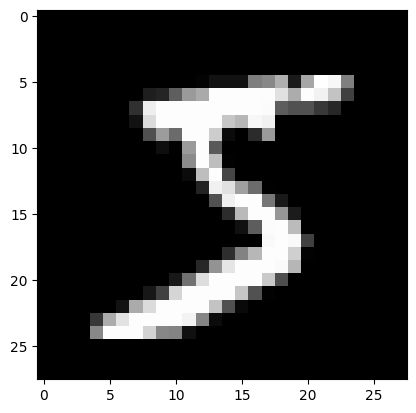

In [76]:
plt.imshow(train_img[0], cmap='gray')
plt.show()

In [77]:
test_img = test_img.reshape(test_img.shape[0], -1)

In [78]:
train_img = train_img.reshape(train_img.shape[0], -1)

In [79]:
train_img #таким образом, все изображения у нас выпрямленные

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(60000, 784), dtype=uint8)

In [80]:
minmax = MinMaxScaler()
train_img = minmax.fit_transform(train_img)
test_img = minmax.transform(test_img)

### **Transforming up to 2 dimensions**

In [81]:
silh_acc_df = pd.DataFrame(columns=['model', 'knn_acc', 'silh_score']).reset_index(drop=True)

#### **PCA**

In [82]:
pca = PCA(n_components=3, random_state=21)
pca_train_img = pca.fit_transform(train_img)
pca_test_img = pca.transform(test_img)

In [83]:
pca_train_img

array([[ 0.48601011,  1.22617368,  0.09613393],
       [ 3.96752299,  1.15630208, -2.33858613],
       [-0.20333178, -1.53793402,  0.73925374],
       ...,
       [-0.69824888, -0.62775763,  1.01024766],
       [ 0.5121807 ,  0.02192911, -2.01513225],
       [-0.68014101,  0.09693645, -2.18046608]], shape=(60000, 3))

In [157]:
example = train.data[0].numpy().reshape(1, -1)
expected_vector = pca.transform(minmax.transform(example))

joblib.dump(
    {
        'model': pca,
        'scaler': minmax,
        'example': example,
        'expected_vector': expected_vector,
    },
    'mnist_pca.joblib',
)

print('Ожидаемый вектор:', expected_vector)

Ожидаемый вектор: [[0.48601011 1.22617368 0.09613393]]


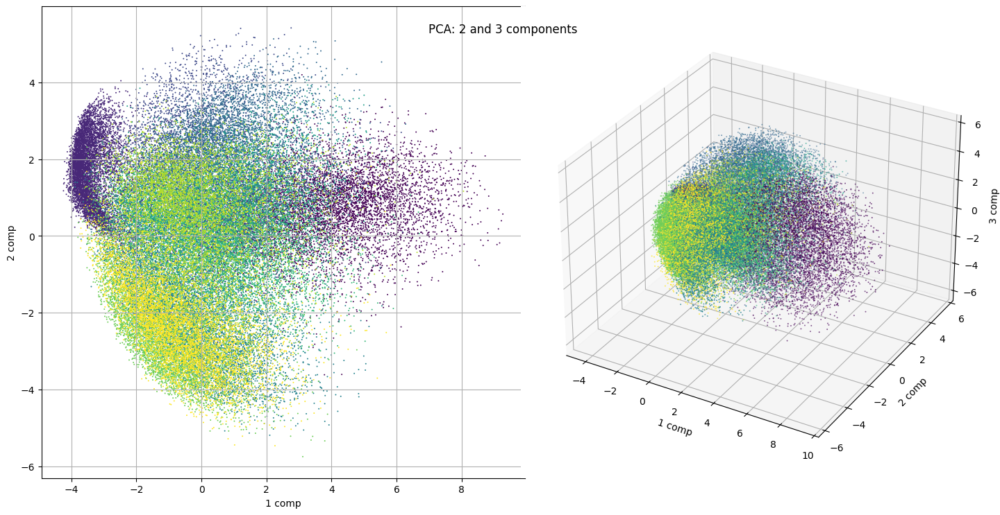

In [84]:
importlib.reload(methods)
from methods import draw_scatterplot

draw_scatterplot(pca_train_img, target_train_img, method='PCA')

In [85]:
knn = KNeighborsClassifier()
knn.fit(pca_train_img[:, :2], target_train_img);

In [86]:
report = classification_report(target_test_img, knn.predict(pca_test_img[:, :2]), output_dict=True)
silh_score = silhouette_score(pca_train_img[:, :2], target_train_img)

In [87]:
silh_acc_df.loc[len(silh_acc_df)] = ['PCA', report['accuracy'], silh_score] #вывод сравнения моделей будет в самом конце блока

#### **SVD**

In [88]:
svd = TruncatedSVD(n_components=3, algorithm='arpack', random_state=21)
svd_train_img = svd.fit_transform(train_img)
svd_test_img = svd.transform(test_img)

In [89]:
svd_train_img

array([[ 6.49823506,  0.18608574,  1.20903864],
       [ 6.87647585, -3.6689079 ,  1.20821916],
       [ 3.14050314, -1.32359644, -1.47838164],
       ...,
       [ 4.90765945,  0.55734851, -0.63394267],
       [ 4.38714042, -1.28525712,  0.05815644],
       [ 4.59275749,  0.52432988,  0.0839715 ]], shape=(60000, 3))

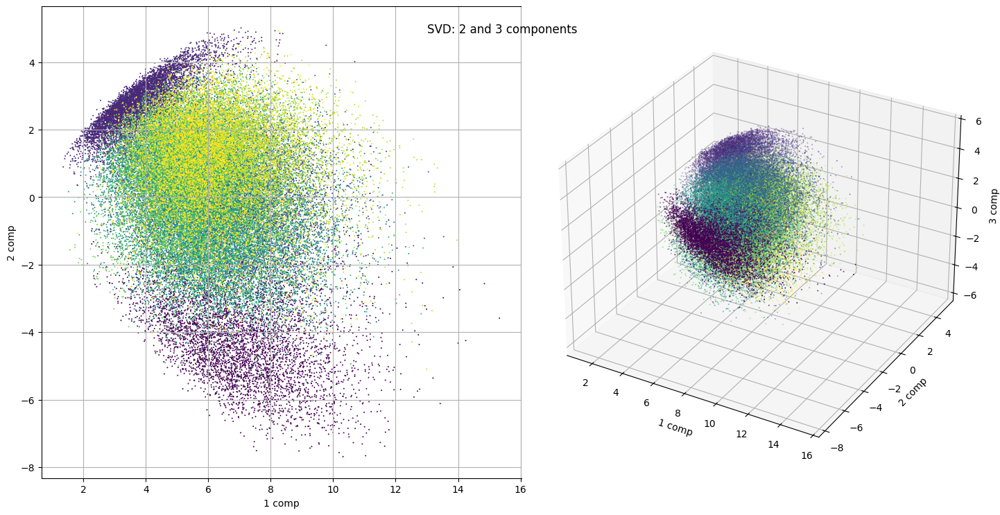

In [90]:
importlib.reload(methods)
from methods import draw_scatterplot

draw_scatterplot(svd_train_img, target_train_img, method='SVD')

In [91]:
knn.fit(svd_train_img[:, :2], target_train_img);

In [92]:
report = classification_report(target_test_img, knn.predict(svd_test_img[:, :2]), output_dict=True)
silh_score = silhouette_score(svd_train_img[:, :2], target_train_img)

In [93]:
silh_acc_df.loc[len(silh_acc_df)] = ['SVD', report['accuracy'], silh_score]

#### **Randomized-SVD**

In [94]:
svd = TruncatedSVD(n_components=3, random_state=21)
rsvd_train_img = svd.fit_transform(train_img)
rsvd_test_img = svd.transform(test_img)

In [95]:
rsvd_train_img

array([[ 6.49823506,  0.18625233,  1.20859558],
       [ 6.87647585, -3.6689623 ,  1.20825901],
       [ 3.14050314, -1.32361093, -1.47837035],
       ...,
       [ 4.90765945,  0.55741857, -0.63409806],
       [ 4.38714042, -1.28525311,  0.05811689],
       [ 4.59275749,  0.52434557,  0.08401385]], shape=(60000, 3))

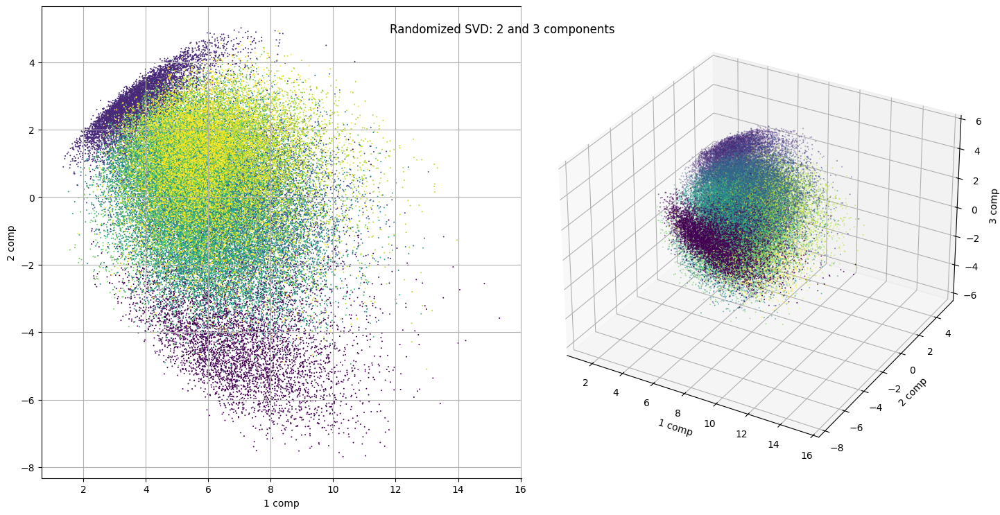

In [96]:
importlib.reload(methods)
from methods import draw_scatterplot

draw_scatterplot(rsvd_train_img, target_train_img, method='Randomized SVD')

In [97]:
knn.fit(rsvd_train_img[:, :2], target_train_img);

In [98]:
report = classification_report(target_test_img, knn.predict(rsvd_test_img[:, :2]), output_dict=True)
silh_score = silhouette_score(rsvd_train_img[:, :2], target_train_img)

In [99]:
silh_acc_df.loc[len(silh_acc_df)] = ['Randomized-SVD', report['accuracy'], silh_score]

#### **TSNE**

In [100]:
tsne = TSNE(n_components=2, random_state=21, n_jobs=-1)
tsne_train_img = tsne.fit_transform(train_img)

In [101]:
tsne_train_img

array([[ 36.938778  ,  -0.40848175],
       [ 73.27646   ,  39.931557  ],
       [ 29.43232   , -72.25014   ],
       ...,
       [ 32.693893  ,  -0.11832504],
       [ 65.0885    , -52.421528  ],
       [-41.760998  ,  11.55642   ]], shape=(60000, 2), dtype=float32)

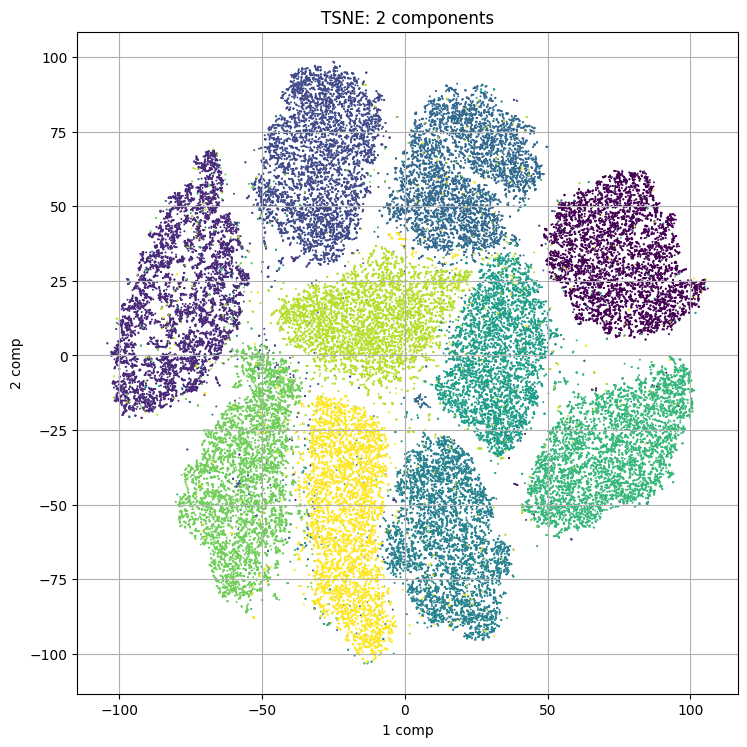

In [102]:
importlib.reload(methods)
from methods import draw_scatterplot

draw_scatterplot(tsne_train_img, target_train_img, method='TSNE')

In [103]:
tsne_train, tsne_test, y_tr_tsne, y_tst_tsne = train_test_split(tsne_train_img, target_train_img, test_size=0.3, shuffle=True, random_state=21)

In [104]:
knn.fit(tsne_train, y_tr_tsne);

In [105]:
report = classification_report(y_tst_tsne, knn.predict(tsne_test), output_dict=True)
silh_score = silhouette_score(tsne_train_img, target_train_img)

In [106]:
silh_acc_df.loc[len(silh_acc_df)] = ['TSNE', report['accuracy'], silh_score]

#### **UMAP**

In [107]:
umap = UMAP(n_components=2, n_jobs=-1)
umap_train_img = umap.fit_transform(train_img)
umap_test_img = umap.transform(test_img)

In [108]:
umap_train_img

array([[ 4.077536  ,  4.9167757 ],
       [14.891829  ,  2.112495  ],
       [ 1.1392406 , -4.283914  ],
       ...,
       [ 3.781687  ,  4.7218513 ],
       [11.189684  ,  7.989263  ],
       [-0.38471413,  4.3375382 ]], shape=(60000, 2), dtype=float32)

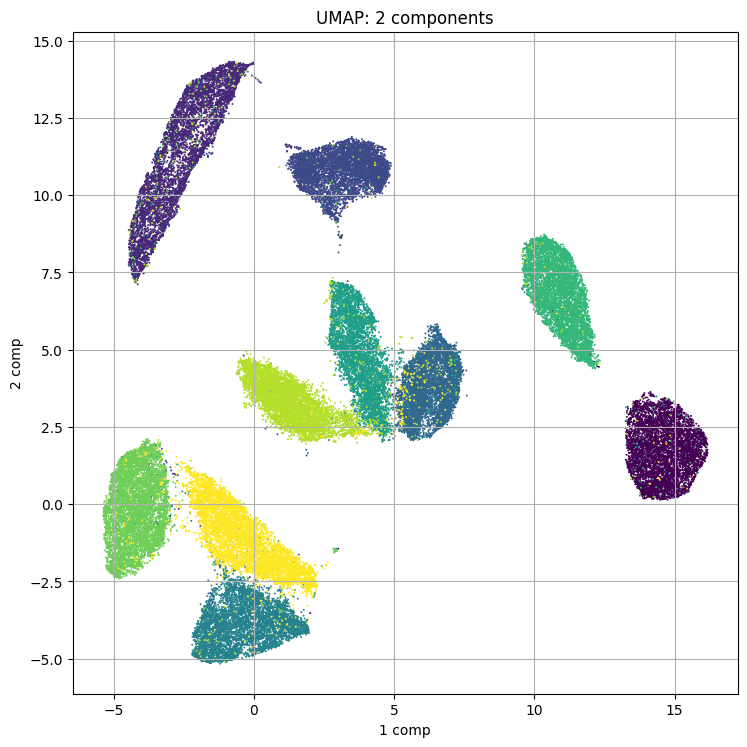

In [109]:
draw_scatterplot(umap_train_img, target_train_img, method='UMAP')

In [110]:
knn.fit(umap_train_img, target_train_img);

In [111]:
report = classification_report(target_test_img, knn.predict(umap_test_img), output_dict=True)
silh_score = silhouette_score(umap_train_img, target_train_img)

In [112]:
silh_acc_df.loc[len(silh_acc_df)] = ['UMAP', report['accuracy'], silh_score]

#### **LLE**

In [113]:
lle = LocallyLinearEmbedding(n_components=3, random_state=21, n_jobs=-1)
lle_train_img = lle.fit_transform(train_img)
lle_test_img = lle.transform(test_img)

In [114]:
lle_train_img

array([[-0.00020534, -0.00211118,  0.00310058],
       [ 0.00917405,  0.00857562,  0.00021427],
       [-0.00321875,  0.00128328, -0.0033742 ],
       ...,
       [ 0.00020398, -0.00260404,  0.00297312],
       [ 0.00656164, -0.00935437, -0.00434662],
       [-0.00154188, -0.00046246,  0.00318972]], shape=(60000, 3))

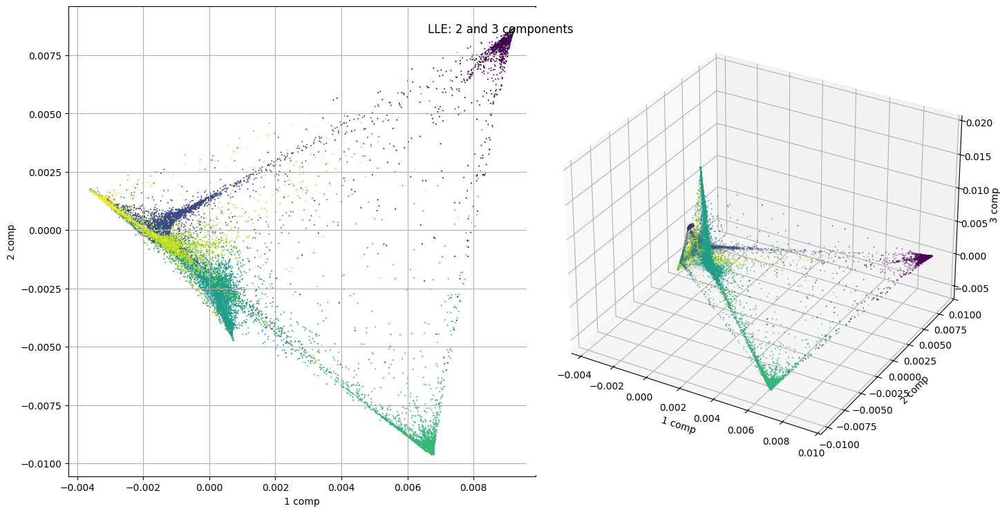

In [115]:
importlib.reload(methods)
from methods import draw_scatterplot

draw_scatterplot(lle_train_img, target_train_img, method='LLE')

In [116]:
knn.fit(lle_train_img[:, :2], target_train_img);

In [117]:
report = classification_report(target_test_img, knn.predict(lle_test_img[:, :2]), output_dict=True)
silh_score = silhouette_score(lle_train_img[:, :2], target_train_img)

In [118]:
silh_acc_df.loc[len(silh_acc_df)] = ['LLE', report['accuracy'], silh_score]

In [119]:
silh_acc_df.sort_values(by=['silh_score', 'knn_acc'], ascending=False).reset_index(drop=True)

,model,knn_acc,silh_score
0,UMAP,0.955800,0.509048
1,LLE,0.883500,0.382704
2,TSNE,0.970889,0.367426
3,PCA,0.424300,0.023479
4,Randomized-SVD,0.304000,-0.028255
5,SVD,0.304000,-0.028255


### **The best algorithm is UMAP!** <br>
Я оценивала модель с точки зрения компактности и разделимости классов. Метрики точности по KNN и коэффициент силуета дополняют друг друга: knn оценивала, насколько по соседям возможно угадать их класс. Точечно оценивала компактность классов. Коэффициент силуета оценивал глобальную структуру кластеров на основе истинных меток.


### **Image compression using SVD**

In [120]:
dog_image = cv2.imread('data/dog.png', cv2.IMREAD_GRAYSCALE)
cat_image = cv2.imread('data/cat.jpg', cv2.IMREAD_GRAYSCALE)
flowers_image = cv2.imread('data/flowers.jpg', cv2.IMREAD_GRAYSCALE)

In [121]:
print(dog_image.shape)
print(cat_image.shape)
print(flowers_image.shape)

(427, 640)
(484, 728)
(612, 612)


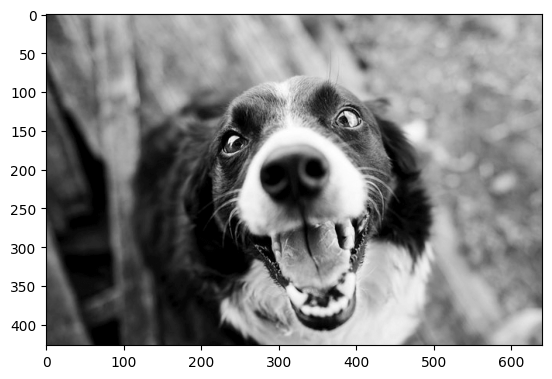

In [153]:
plt.imshow(dog_image, cmap='gray');

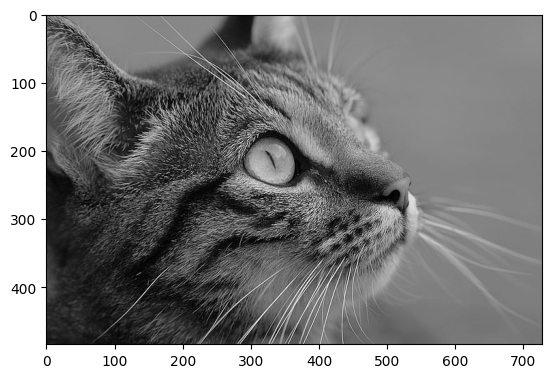

In [154]:
plt.imshow(cat_image, cmap='gray');

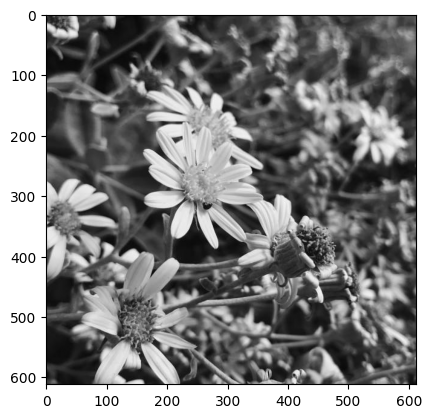

In [155]:
plt.imshow(flowers_image, cmap='gray');

In [125]:
importlib.reload(methods)
from methods import draw_k_images

In [126]:
k = 12
rng = np.random.default_rng(seed=21)
rang_seq = np.sort(rng.choice(np.arange(1, 100), k, replace=False))

#### **DOG**

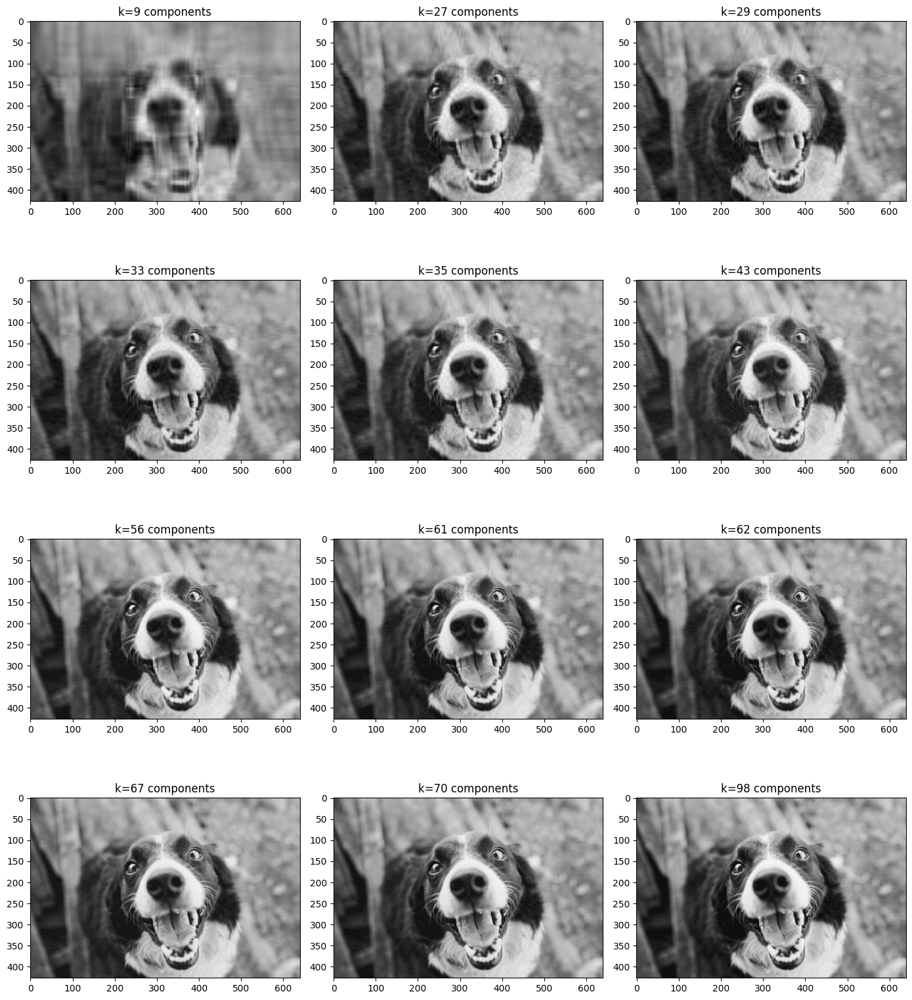

In [127]:
comp_dog = np.linalg.svd(dog_image, full_matrices=False)
draw_k_images(comp_dog, k, rang_seq=rang_seq)

**Log Spectrum for dog**

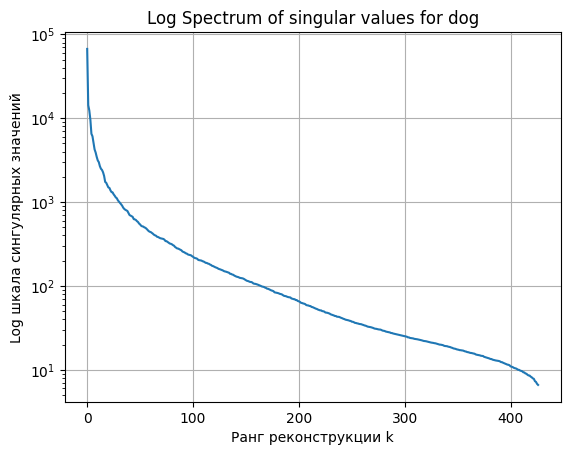

In [128]:
plt.plot(comp_dog.S)
plt.yscale('log')
plt.title(f"Log Spectrum of singular values for dog")
plt.xlabel('Ранг реконструкции k')
plt.ylabel('Log шкала сингулярных значений')
plt.grid(True)
plt.show()

**Explained variance for dog**

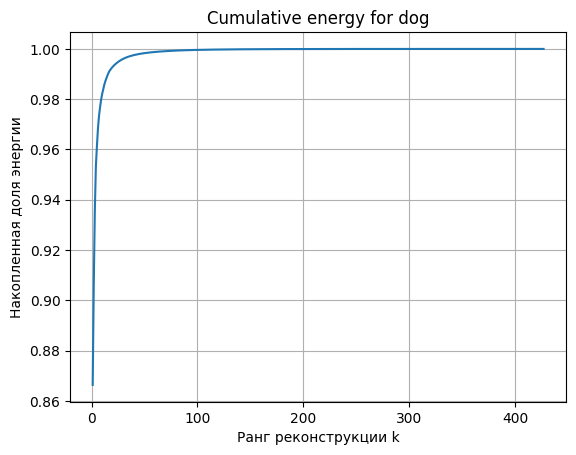

In [129]:
variances_S = comp_dog.S ** 2
squared_sum_S = np.sum(variances_S)
cumsum_ratio_d = np.cumsum(variances_S / squared_sum_S)
rangs = np.arange(1, len(cumsum_ratio_d) + 1)

plt.plot(rangs, cumsum_ratio_d)
plt.xlabel('Ранг реконструкции k')
plt.ylabel('Накопленная доля энергии')
plt.title('Cumulative energy for dog')
plt.grid(True)
plt.show()

**Зададим порог оценки качества рекострукции: 99%**

In [130]:
rang_99p_dog = rangs[(cumsum_ratio_d * 100).astype(int) == 99][0]
rang_99p_dog.item()

16

**Для приближенного восстановления собачки достаточно примерно 16 компонент**

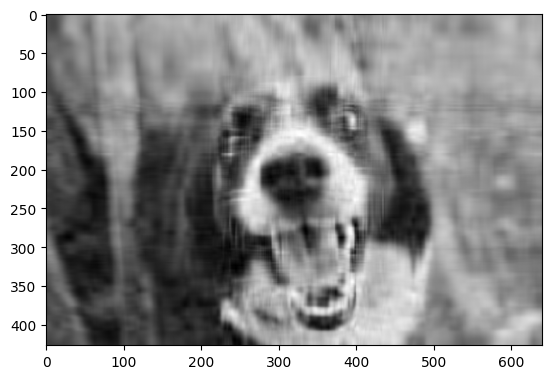

In [131]:
plt.imshow(comp_dog.U[:, :rang_99p_dog] @ np.diag(comp_dog.S[:rang_99p_dog]) @ comp_dog.Vh[:rang_99p_dog, :], cmap='gray');

#### **CAT**

In [132]:
comp_cat = np.linalg.svd(cat_image, full_matrices=False)

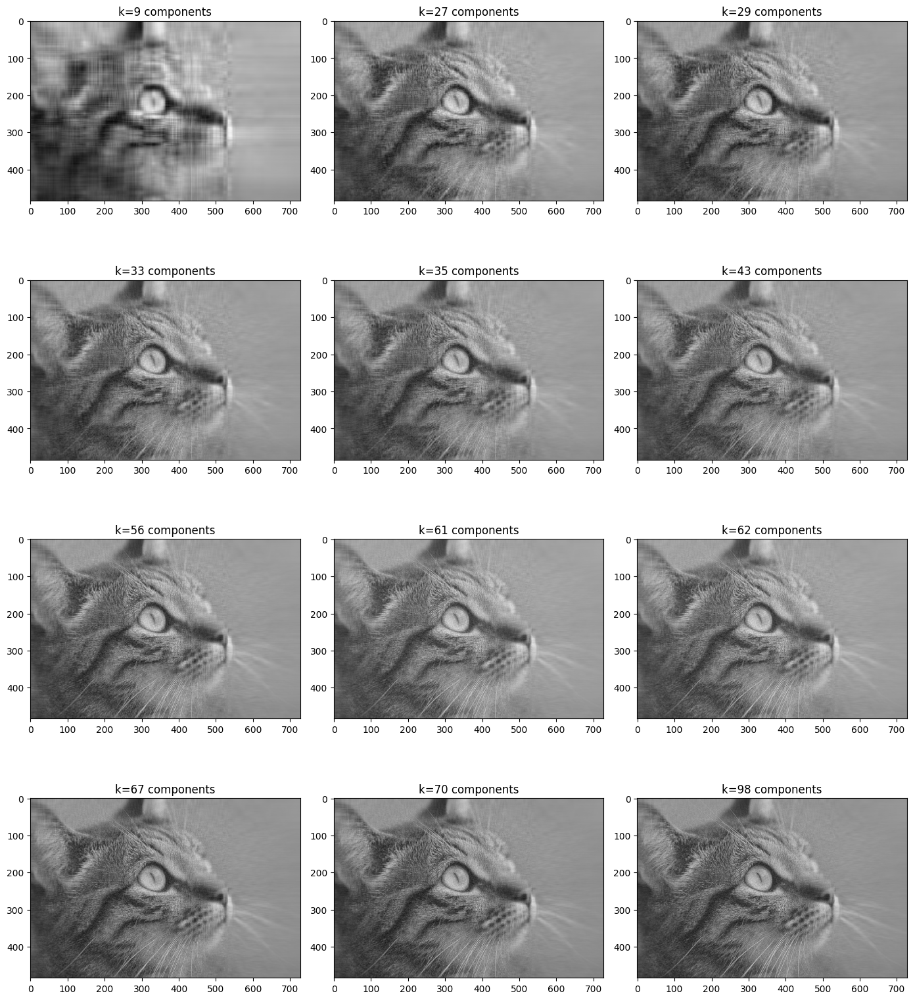

In [133]:
draw_k_images(comp_cat, k, rang_seq=rang_seq)

**Log spectrum for cat**

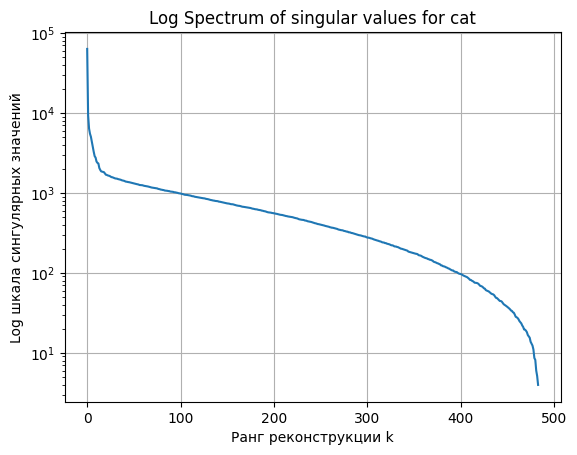

In [134]:
plt.plot(comp_cat.S)
plt.yscale('log')
plt.title(f"Log Spectrum of singular values for cat")
plt.xlabel('Ранг реконструкции k')
plt.ylabel('Log шкала сингулярных значений')
plt.grid(True)
plt.show()

**Explained variance of cat**

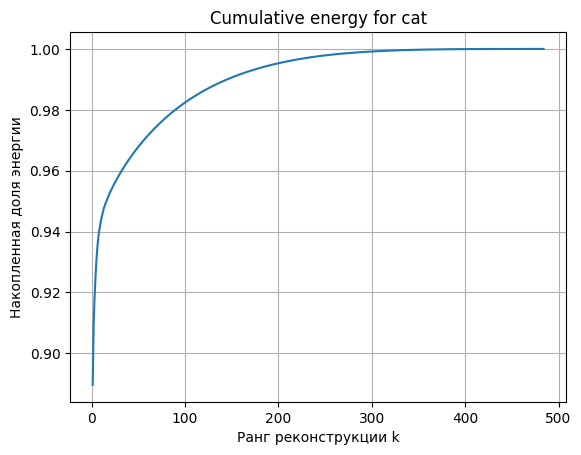

In [135]:
variances_S = comp_cat.S ** 2
squared_sum_S = np.sum(variances_S)
cumsum_ratio_с = np.cumsum(variances_S / squared_sum_S)
rangs = np.arange(1, len(cumsum_ratio_с) + 1)

plt.plot(rangs, cumsum_ratio_с)
plt.xlabel('Ранг реконструкции k')
plt.ylabel('Накопленная доля энергии')
plt.title('Cumulative energy for cat')
plt.grid(True)
plt.show()

In [136]:
rang_99p_cat = rangs[(cumsum_ratio_с * 100).astype(int) == 99][0]
rang_99p_cat.item()

146

**Для приближенного восстановления кошки достаточно примерно 146 компонент**

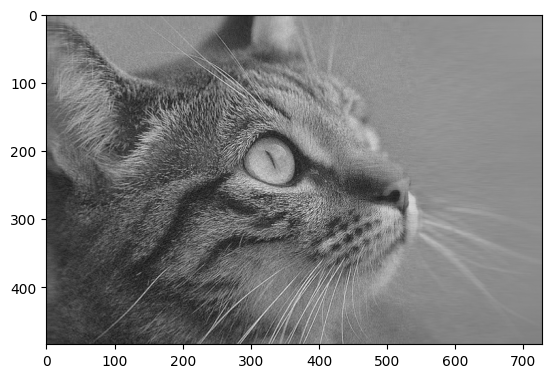

In [137]:
plt.imshow(comp_cat.U[:, :rang_99p_cat] @ np.diag(comp_cat.S[:rang_99p_cat]) @ comp_cat.Vh[:rang_99p_cat, :], cmap='gray');

#### **FLOWERS**

In [138]:
comp_flowers = np.linalg.svd(flowers_image, full_matrices=False)

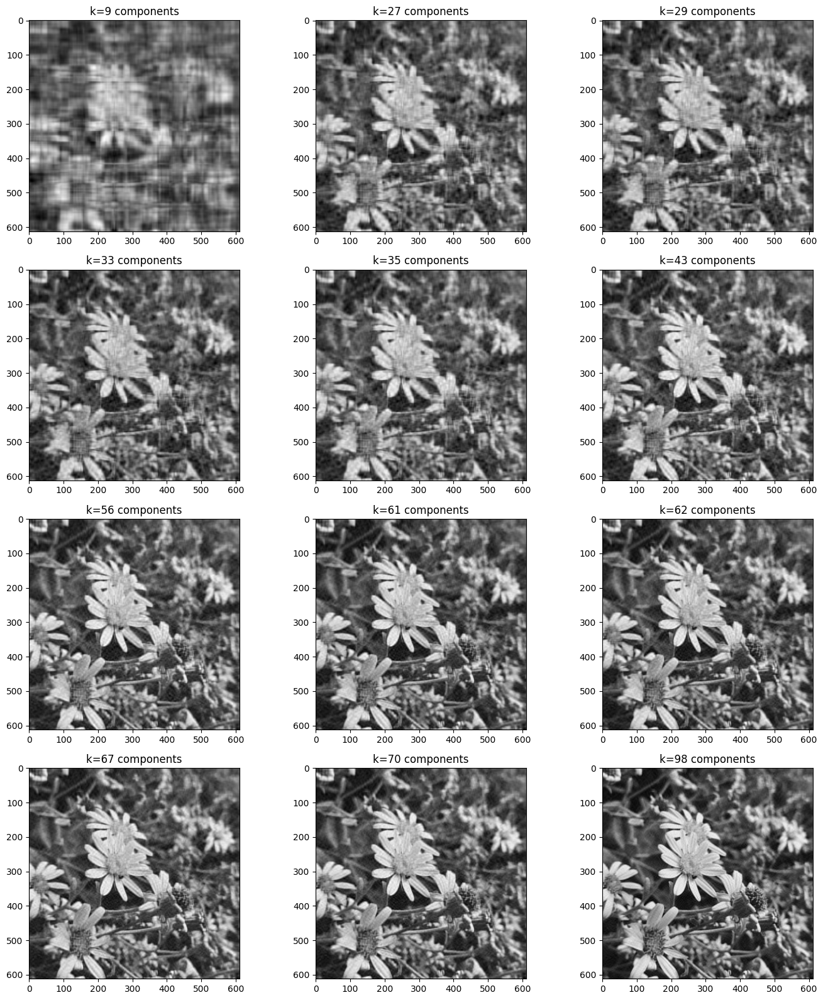

In [139]:
draw_k_images(comp_flowers, k, rang_seq=rang_seq)

**Log spectrum of singular values for flowers**

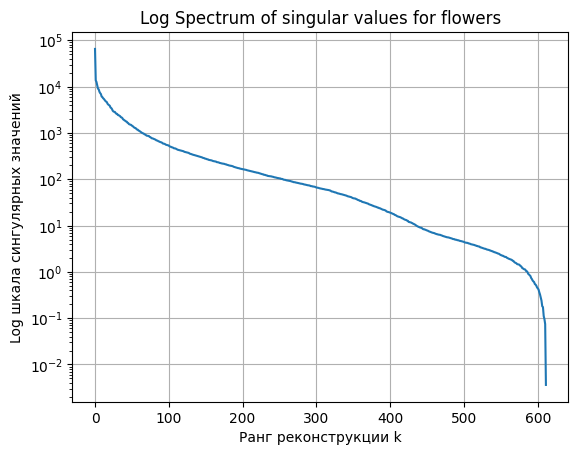

In [140]:
plt.plot(comp_flowers.S)
plt.yscale('log')
plt.title(f"Log Spectrum of singular values for flowers")
plt.xlabel('Ранг реконструкции k')
plt.ylabel('Log шкала сингулярных значений')
plt.grid(True)
plt.show()

**Explained variance for flowers**

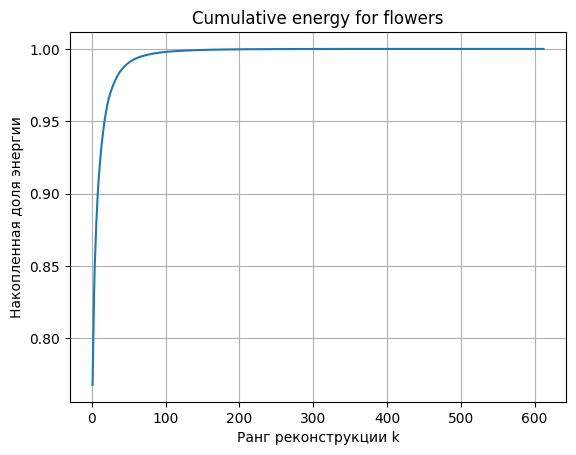

In [141]:
variances_S = comp_flowers.S ** 2
squared_sum_S = np.sum(variances_S)
cumsum_ratio_f = np.cumsum(variances_S / squared_sum_S)
rangs = np.arange(1, len(cumsum_ratio_f) + 1)

plt.plot(rangs, cumsum_ratio_f)
plt.xlabel('Ранг реконструкции k')
plt.ylabel('Накопленная доля энергии')
plt.title('Cumulative energy for flowers')
plt.grid(True)
plt.show()

In [142]:
rang_99p_flowers = rangs[(cumsum_ratio_f * 100).astype(int) == 99][0]
rang_99p_flowers.item()

49

**Для приближенного восстановления цветочков достаточно примерно 49 компонент**

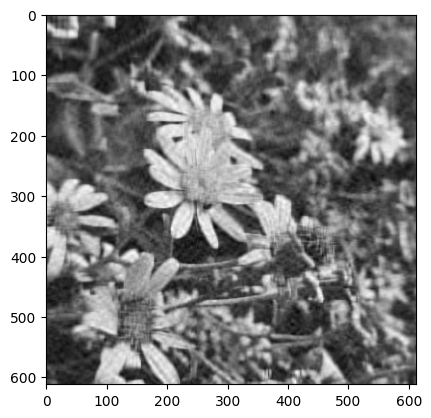

In [143]:
plt.imshow(comp_flowers.U[:, :rang_99p_flowers] @ np.diag(comp_flowers.S[:rang_99p_flowers]) @ comp_flowers.Vh[:rang_99p_flowers, :], cmap='gray');

**Объясненная дисперсия - это мера разброса данных, которые проецируется на каждую компоненту (собственный вектор) пространства пониженной размерности. Чем дисперсия для компоненты больше, тем больше разброс данных вдоль компоненты. Поэтому, чаще всего, для приближённого восстановления достаточно части компонент, так как с увеличением компонент убывает информация, которую они в себе несут. Самая главная информация об изображении объясняется определенным кол-вом начальных компонент**

### **Background detection using SVD**

In [144]:
cap = cv2.VideoCapture('data/Video_008.avi')

frames = []

while True:
    success, frame = cap.read()

    if not success:
        break

    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    frames.append(gray_frame)

cap.release()
frames = np.stack(frames)
frames.shape

(792, 240, 320)

In [145]:
frames_f = frames.reshape(frames.shape[0], -1)

In [146]:
frames_f

array([[166, 176, 191, ..., 110,  80,  68],
       [170, 180, 192, ..., 110,  80,  68],
       [169, 182, 195, ...,  96, 102, 102],
       ...,
       [249, 251, 251, ...,  58,  66,  71],
       [249, 251, 251, ...,  61,  63,  65],
       [249, 251, 251, ...,  62,  55,  59]],
      shape=(792, 76800), dtype=uint8)

In [147]:
frames_svd = np.linalg.svd(frames_f, full_matrices=False)

In [148]:
frames_svd.U.shape, frames_svd.S.shape, frames_svd.Vh.shape

((792, 792), (792,), (792, 76800))

**First frame reconstruction**

**Каждая строка frames_f соответствует одному кадру. Для восстановления первого кадра берем первую строку U и оставляем первые k компонент разложения. Полученный вектор возвращаем к исходному размеру кадра. Сравним ранги 1, 2, 3, 5 и 10.**

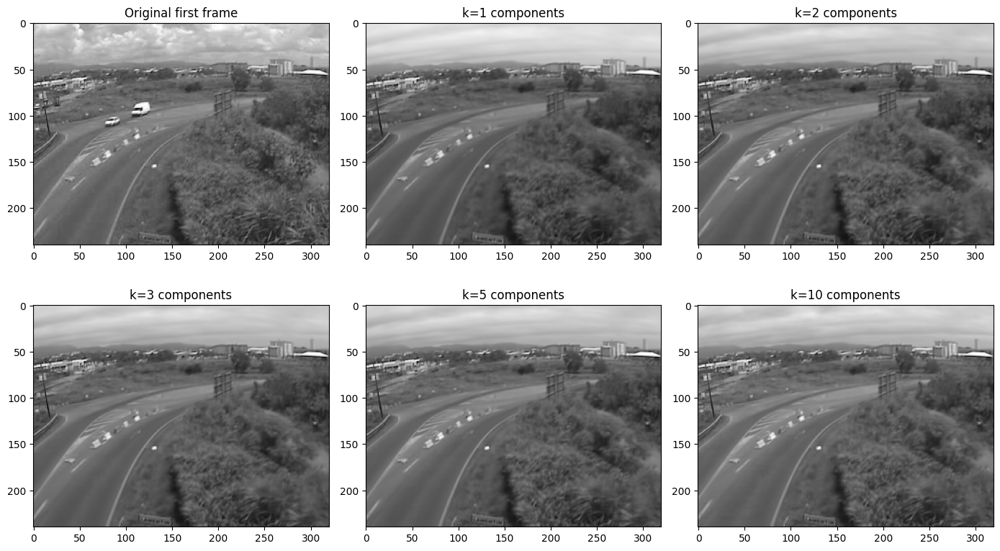

In [152]:
first_frame = frames[0]
rang_seq_video = [1, 2, 3, 5, 10]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

axes[0].imshow(first_frame, cmap='gray')
axes[0].set_title('Original first frame')

for i, rang in enumerate(rang_seq_video, start=1):
    restored_frame = (
        frames_svd.U[0, :rang]
        @ np.diag(frames_svd.S[:rang])
        @ frames_svd.Vh[:rang, :]
    ).reshape(first_frame.shape)

    axes[i].imshow(restored_frame, cmap='gray')
    axes[i].set_title(f'k={rang} components')

fig.tight_layout()
plt.show()

**Background reconstruction**

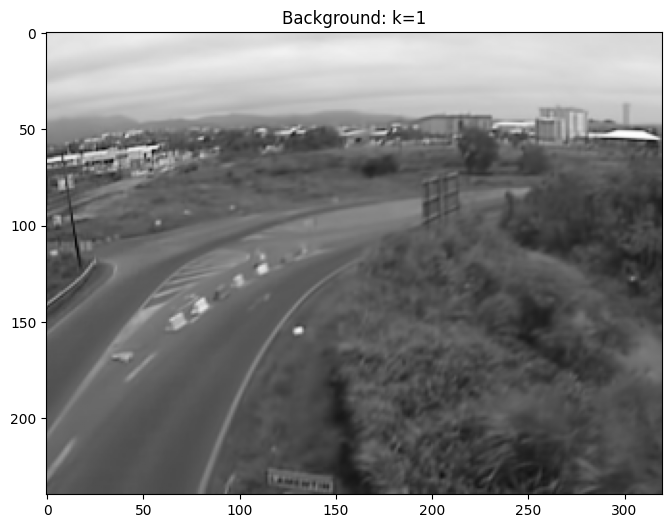

In [151]:
background_rank = 1
background = (
    frames_svd.U[0, :background_rank]
    @ np.diag(frames_svd.S[:background_rank])
    @ frames_svd.Vh[:background_rank, :]
).reshape(first_frame.shape)

plt.figure(figsize=(8, 6))
plt.imshow(background, cmap='gray')
plt.title(f'Background: k={background_rank}')
plt.show()

**Для приближенного выделения фона достаточно ранга 1. На восстановленном кадре сохраняются дорога, здания и основная структура растительности, а две машины из исходного первого кадра практически исчезают. Неподвижная часть сцены повторяется во многих кадрах и дает основной вклад в первый компонент разложения.**

**При увеличении ранга добавляются компоненты, описывающие изменения между кадрами. Восстановление постепенно приближается к исходному кадру, включая движущиеся объекты. Поэтому для выделения фона выбираем небольшой ранг. Полученный фон является приближением: детали неба и растительности сглажены, возможны слабые следы движения.**